# 🍽️ Restaurante favorito ou o novo da esquina? — ε-greedy na prática

Você acabou de se mudar e tem **5 restaurantes** no bairro. Cada um tem uma qualidade "verdadeira" que você **não conhece**: cada jantar te dá uma nota de 0 a 10, que varia de noite para noite. Você vai jantar fora **todas as noites** durante um ano.

Repetir o restaurante que parece melhor (**explotar**) ou testar outro (**explorar**)? Esse é o dilema dos slides 82–85.

| Conceito | Aqui |
|---|---|
| **Ação** | escolher um dos 5 restaurantes |
| **Recompensa** | a nota do jantar (0 a 10) |
| **Valor estimado** $Q(a)$ | a média das notas que você já tirou naquele restaurante |
| **Política ε-greedy** | com probabilidade ε, um restaurante ao acaso; senão, o de maior $Q(a)$ |

> Este é o problema de RL mais simples que existe: **um único estado** (toda noite é igual) — o famoso *bandido multibraço*. Sem a parte "sequencial", sobra só o dilema puro de explorar × explotar.

**Roteiro:** 1) você joga · 2) o agente ε-greedy · 3) a corrida dos ε · 4) o que o agente "acredita" · 5) e se o restaurante mudar?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, clear_output
import ipywidgets as widgets

RESTAURANTES = ['Cantina da Nonna', 'Sushi do Japa', 'Boteco do Zé', 'Vegano Verde', 'Churrascaria Gaúcha']
CORES = ['#E57373', '#64B5F6', '#FFB74D', '#81C784', '#BA68C8']
QUALIDADE = np.array([6.0, 7.5, 5.0, 6.8, 7.0])   # a "verdade" — o agente NÃO vê isto
RUIDO = 1.5                                       # a mesma cozinha varia de noite para noite


def jantar(restaurante, qualidade=QUALIDADE):
    """O ambiente: devolve a nota de um jantar (recompensa)."""
    return float(np.clip(np.random.normal(qualidade[restaurante], RUIDO), 0, 10))


print('Ambiente pronto: 5 restaurantes, notas de 0 a 10. A qualidade verdadeira está escondida.')

Ambiente pronto: 5 restaurantes, notas de 0 a 10. A qualidade verdadeira está escondida.


## 1. Você joga: 20 jantares

Clique num restaurante para jantar lá. Você vê a nota de cada jantar e a sua média. Depois de 20 noites, a verdade é revelada.

> **Estratégia:** você vai testar todos? Quantas vezes cada um antes de decidir?

In [2]:
# @title Os botões do jogo (rode e siga em frente)
def jogar_jantares(n_noites=20):
    notas = {i: [] for i in range(5)}
    estado = {'noite': 0}
    botoes = [widgets.Button(description=nome, layout=widgets.Layout(width='170px'),
                             style={'button_color': cor}) for nome, cor in zip(RESTAURANTES, CORES)]
    painel, resultado = widgets.HTML(), widgets.HTML()

    def atualizar():
        linhas = ''.join(
            f'<tr><td>{RESTAURANTES[i]}</td><td>{len(notas[i])}</td>'
            f'<td>{(np.mean(notas[i]) if notas[i] else float("nan")):.1f}</td>'
            f'<td>{" ".join(f"{x:.0f}" for x in notas[i][-8:])}</td></tr>' for i in range(5))
        total = sum(sum(v) for v in notas.values())
        painel.value = (f'<b>Noite {estado["noite"]} de {n_noites}</b> · soma das notas: <b>{total:.0f}</b>'
                        '<table style="font-family:monospace" cellpadding="4"><tr style="background:#ECEFF1">'
                        '<th>restaurante</th><th>visitas</th><th>sua média Q(a)</th><th>últimas notas</th></tr>'
                        f'{linhas}</table>')

    def escolher(i):
        if estado['noite'] >= n_noites:
            return
        notas[i].append(jantar(i))
        estado['noite'] += 1
        atualizar()
        if estado['noite'] == n_noites:
            total = sum(sum(v) for v in notas.values())
            melhor = int(np.argmax(QUALIDADE))
            verdade = ''.join(f'<li>{RESTAURANTES[k]}: <b>{QUALIDADE[k]:.1f}</b>'
                              f'{" ⭐ o melhor" if k == melhor else ""}</li>' for k in np.argsort(-QUALIDADE))
            resultado.value = (f'<h4>🔍 A verdade revelada</h4><ul>{verdade}</ul>'
                               f'Sua soma: <b>{total:.0f}</b> · jantando sempre no melhor, a soma esperada seria '
                               f'<b>{QUALIDADE[melhor] * n_noites:.0f}</b>. A diferença é o seu '
                               f'<b>arrependimento</b> (o custo de aprender).')
            for b in botoes:
                b.disabled = True

    for i, b in enumerate(botoes):
        b.on_click(lambda _, i=i: escolher(i))
    atualizar()
    display(widgets.VBox([widgets.HBox(botoes[:3]), widgets.HBox(botoes[3:]), painel, resultado]))

In [ ]:
jogar_jantares()

## 2. O agente ε-greedy (slide 85)

O agente segue o fluxograma do slide 85 a cada noite:

1. sorteia um número entre 0 e 1;
2. se for **menor que ε → explora**: restaurante ao acaso;
3. senão → **explota**: o restaurante com a maior média $Q(a)$;
4. janta, recebe a nota e **atualiza a média** daquele restaurante.

A média é atualizada sem guardar todas as notas, com uma conta que você vai reencontrar no Q-Learning:

$$Q(a) \leftarrow Q(a) + \frac{1}{n}\,\big[\,\text{nota} - Q(a)\,\big] \qquad \text{(estimativa nova = antiga + passo × erro)}$$

In [3]:
def epsilon_greedy(Q, epsilon):
    if np.random.rand() < epsilon:                  # explora
        return np.random.randint(len(Q))
    melhores = np.flatnonzero(Q == Q.max())         # explota (empate: sorteia entre os melhores)
    return int(np.random.choice(melhores))


def um_ano(epsilon=0.1, noites=365, qualidade=QUALIDADE, decaimento=None, alfa=None, mudanca=None):
    """Simula um ano de jantares. Devolve as notas e se cada escolha foi o melhor restaurante da noite.
    decaimento: ε é multiplicado por este fator toda noite (None = ε fixo).
    alfa: passo fixo da atualização (None = média simples 1/n).
    mudanca: (noite, restaurante, nova_qualidade) — um restaurante muda no meio do ano."""
    qualidade = qualidade.copy()
    Q, n = np.zeros(len(qualidade)), np.zeros(len(qualidade))
    notas, acertos, historico_Q = [], [], []
    for noite in range(noites):
        if mudanca and noite == mudanca[0]:
            qualidade[mudanca[1]] = mudanca[2]
        a = epsilon_greedy(Q, epsilon)
        r = jantar(a, qualidade)
        n[a] += 1
        passo = (1 / n[a]) if alfa is None else alfa
        Q[a] += passo * (r - Q[a])                  # estimativa ← estimativa + passo × (nota − estimativa)
        notas.append(r)
        acertos.append(a == np.argmax(qualidade))
        historico_Q.append((Q.copy(), n.copy()))
        if decaimento:
            epsilon *= decaimento
    return np.array(notas), np.array(acertos), historico_Q


np.random.seed(0)
for ano in range(1, 9):
    notas, acertos, _ = um_ano(epsilon=0.1)
    print(f"Ano {ano} com ε = 0,1: nota média {notas.mean():.2f} | jantou no melhor restaurante em {acertos.mean():4.0%} das noites")

Ano 1 com ε = 0,1: nota média 6.73 | jantou no melhor restaurante em   5% das noites
Ano 2 com ε = 0,1: nota média 6.90 | jantou no melhor restaurante em   2% das noites
Ano 3 com ε = 0,1: nota média 6.95 | jantou no melhor restaurante em  35% das noites
Ano 4 com ε = 0,1: nota média 7.19 | jantou no melhor restaurante em  69% das noites
Ano 5 com ε = 0,1: nota média 7.30 | jantou no melhor restaurante em  88% das noites
Ano 6 com ε = 0,1: nota média 7.45 | jantou no melhor restaurante em  84% das noites
Ano 7 com ε = 0,1: nota média 7.20 | jantou no melhor restaurante em  70% das noites
Ano 8 com ε = 0,1: nota média 7.36 | jantou no melhor restaurante em  92% das noites


Repare como os anos variam: em alguns o agente acha o melhor restaurante cedo; em outros, se apega a um "quase tão bom" (7,0 ou 6,8) e demora a sair dele. **Um ano só pode ser sorte** (slide 131).

## 3. A corrida dos ε

Por isso Simulamos **2.000 anos** para cada estratégia e tiramos a média, noite a noite.

| Estratégia | Comportamento |
|---|---|
| ε = 0 (guloso) | nunca explora: fica no primeiro que pareceu bom |
| ε = 0,01 | explora 1 noite em cada 100 |
| ε = 0,1 | explora 1 noite em cada 10 (o exemplo do slide 84) |
| ε = 0,3 | explora muito |
| ε decaindo | começa em 1 e cai 2% por noite — como nos notebooks de Q-Learning |

> **Palpite (em duplas):** qual estratégia termina o ano jantando mais vezes no melhor restaurante? E qual tem a **maior nota média** no ano?

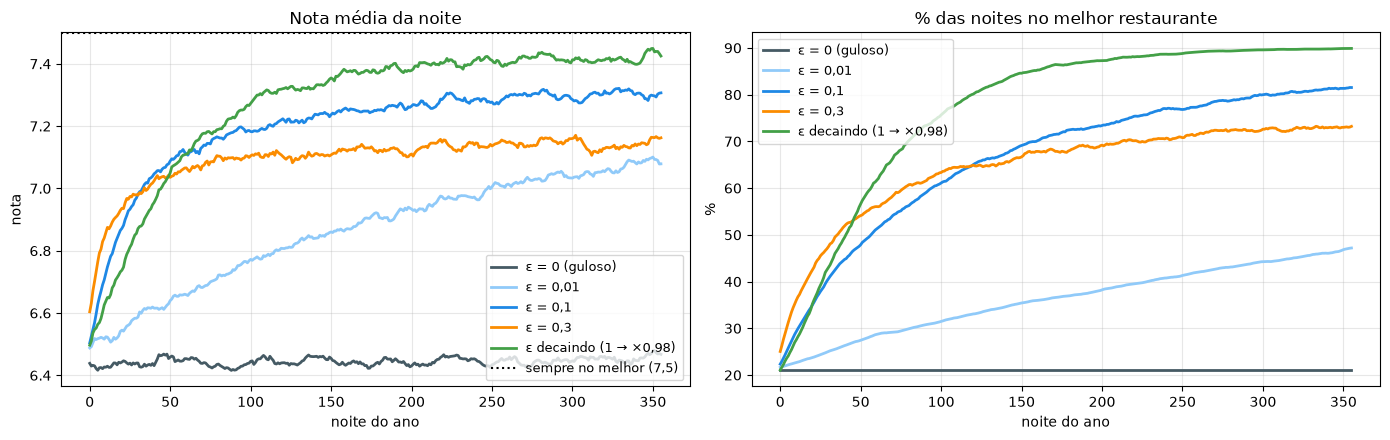

estratégia                nota média no ano   % no melhor (últimos 30 dias)
ε = 0 (guloso)                         6.44                             21%
ε = 0,01                               6.86                             46%
ε = 0,1                                7.19                             81%
ε = 0,3                                7.09                             73%
ε decaindo (1 → ×0,98)                 7.26                             90%


In [4]:
ESTRATEGIAS = {
    'ε = 0 (guloso)': dict(epsilon=0.0),
    'ε = 0,01': dict(epsilon=0.01),
    'ε = 0,1': dict(epsilon=0.1),
    'ε = 0,3': dict(epsilon=0.3),
    'ε decaindo (1 → ×0,98)': dict(epsilon=1.0, decaimento=0.98),
}
N_ANOS = 2000

np.random.seed(1)
curvas = {}
for nome, kw in ESTRATEGIAS.items():
    res = [um_ano(**kw)[:2] for _ in range(N_ANOS)]
    curvas[nome] = (np.mean([r[0] for r in res], axis=0), np.mean([r[1] for r in res], axis=0))

suave = lambda x: np.convolve(x, np.ones(10) / 10, mode='valid')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (nome, (nota, acerto)), cor in zip(curvas.items(), ['#455A64', '#90CAF9', '#1E88E5', '#FB8C00', '#43A047']):
    axes[0].plot(suave(nota), label=nome, color=cor, lw=2)
    axes[1].plot(suave(acerto) * 100, label=nome, color=cor, lw=2)
axes[0].axhline(QUALIDADE.max(), color='k', ls=':', label='sempre no melhor (7,5)')
axes[0].set_title('Nota média da noite'); axes[0].set_ylabel('nota')
axes[1].set_title('% das noites no melhor restaurante'); axes[1].set_ylabel('%')
for ax in axes:
    ax.set_xlabel('noite do ano'); ax.grid(alpha=.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"{'estratégia':24s} {'nota média no ano':>18s} {'% no melhor (últimos 30 dias)':>31s}")
for nome, (nota, acerto) in curvas.items():
    print(f"{nome:24s} {nota.mean():18.2f} {acerto[-30:].mean():31.0%}")

**O que observar**
- **ε = 0 (guloso)** trava no primeiro restaurante que pareceu bom — muitas vezes não é o melhor, e ele nunca descobre.
- **Explorar demais** (ε = 0,3) descobre rápido qual é o melhor, mas continua desperdiçando 30% das noites em restaurantes piores.
- **ε decaindo** explora muito no começo e pouco no fim: costuma juntar o melhor dos dois mundos — é por isso que os notebooks de Q-Learning usam ε que decai.
- Repare que nenhuma estratégia chega a 100% no melhor restaurante: os três melhores (7,5 · 7,0 · 6,8) são parecidos, e as notas variam bastante de noite para noite.

## 4. O que o agente "acredita" ao longo do ano

As barras são as médias $Q(a)$ do agente (ε = 0,1); o traço preto é a qualidade verdadeira. O número em cima é quantas vezes ele foi a cada restaurante.

In [5]:
# @title Animação das crenças do agente
np.random.seed(5)
_, _, historico = um_ano(epsilon=0.1)
noites_mostradas = list(range(0, 30)) + list(range(30, 365, 10))

fig, ax = plt.subplots(figsize=(8, 4), dpi=70)
fig.subplots_adjust(bottom=.18, top=.88)


def quadro(k):
    noite = noites_mostradas[min(k, len(noites_mostradas) - 1)]
    Q, n = historico[noite]
    ax.clear()
    barras = ax.bar(range(5), Q, color=CORES)
    ax.scatter(range(5), QUALIDADE, marker='_', s=900, color='k', zorder=3, label='qualidade verdadeira')
    for i, b in enumerate(barras):
        ax.text(i, max(Q[i], QUALIDADE[i]) + .25, f'{n[i]:.0f}×', ha='center', fontsize=10)
    ax.set_xticks(range(5), [r.split()[0] + '\n' + ' '.join(r.split()[1:]) for r in RESTAURANTES], fontsize=8)
    ax.set_ylim(0, 10.5); ax.set_ylabel('Q(a) = média das notas')
    ax.set_title(f'Noite {noite + 1}: o que o agente acredita (ε = 0,1)', fontweight='bold')
    ax.legend(loc='upper right', fontsize=8)
    return []


anim = animation.FuncAnimation(fig, quadro, frames=len(noites_mostradas) + 5, interval=250)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**Nesta simulação:** nas primeiras semanas o agente ficou preso na Cantina (6,0) sem nunca provar o Sushi (7,5). Só a exploração o levou até lá — e daí em diante ele quase não saiu. Já o Vegano Verde, visitado só 5 vezes no ano, terminou **subestimado** (≈ 6,1, quando vale 6,8).

**Para pensar:** os restaurantes que o agente visita pouco ficam com estimativas **ruins** (às vezes bem abaixo da verdade) — e é justamente por parecerem ruins que ele não volta lá. A exploração é o que corrige esses "preconceitos".

## 5. E se o restaurante mudar? 👨‍🍳

Na noite 100, o **Boteco do Zé** contrata um chef novo e passa de 5,0 para **9,0** — vira de longe o melhor. Quem percebe?

| Agente | Exploração | Como atualiza a média |
|---|---|---|
| A | ε decaindo (para de explorar) | média simples (1/n): toda nota pesa igual, para sempre |
| B | ε = 0,1 fixo | média simples (1/n) |
| C | ε = 0,1 fixo | **passo fixo α = 0,3**: notas recentes pesam mais |

> **Palpite:** qual dos três está jantando no Boteco no fim do ano?

A · ε decaindo + média simples      : no Boteco (o novo melhor) em 0% das últimas 30 noites


B · ε = 0,1 + média simples         : no Boteco (o novo melhor) em 50% das últimas 30 noites


C · ε = 0,1 + passo fixo α = 0,3    : no Boteco (o novo melhor) em 80% das últimas 30 noites


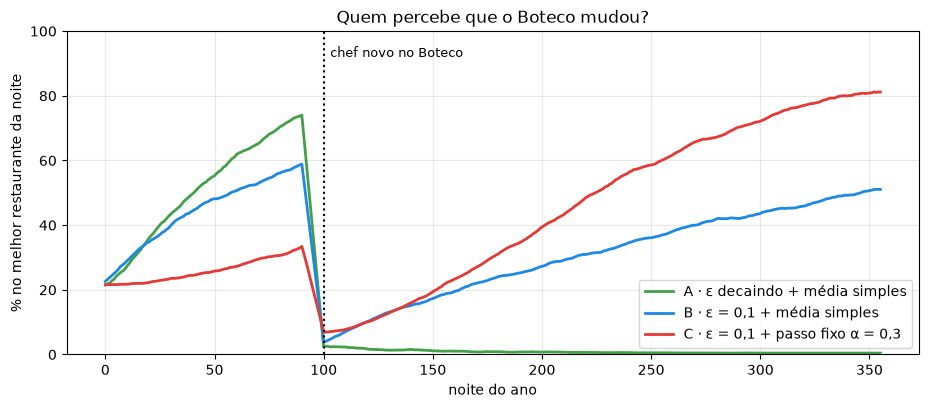

In [6]:
MUDANCA = (100, 2, 9.0)   # noite 100: o Boteco do Zé (restaurante 2) passa a valer 9,0
agentes = {
    'A · ε decaindo + média simples': dict(epsilon=1.0, decaimento=0.98),
    'B · ε = 0,1 + média simples': dict(epsilon=0.1),
    'C · ε = 0,1 + passo fixo α = 0,3': dict(epsilon=0.1, alfa=0.3),
}
np.random.seed(2)
fig, ax = plt.subplots(figsize=(11, 4.2))
for (nome, kw), cor in zip(agentes.items(), ['#43A047', '#1E88E5', '#E53935']):
    acerto = np.mean([um_ano(mudanca=MUDANCA, **kw)[1] for _ in range(1000)], axis=0)
    ax.plot(suave(acerto) * 100, label=nome, color=cor, lw=2)
    print(f"{nome:36s}: no Boteco (o novo melhor) em {acerto[-30:].mean():.0%} das últimas 30 noites")
ax.axvline(100, color='k', ls=':')
ax.text(103, 92, 'chef novo no Boteco', fontsize=9)
ax.set_xlabel('noite do ano'); ax.set_ylabel('% no melhor restaurante da noite')
ax.set_ylim(0, 100); ax.grid(alpha=.3); ax.legend()
ax.set_title('Quem percebe que o Boteco mudou?')
plt.show()

**O que observar**
- **A** parou de explorar: nunca mais volta ao Boteco, então nunca descobre o chef novo.
- **B** ainda explora, mas a média simples carrega meses de notas ruins do Boteco: percebe a mudança **muito devagar**.
- **C** explora **e** dá mais peso ao que é recente (passo fixo α): é o único que se adapta rápido.

É por isso que os notebooks de Q-Learning usam um **ε mínimo** (nunca param de explorar de vez) e um **α fixo** na atualização.

## Para pensar

1. **Slide 84:** "em 1 de cada 10 jantares você testa um restaurante novo". Depois de jogar a seção 1, você acha que explorou demais ou de menos?
2. **Negócio (slide 34):** um sistema de recomendação mostra 80% das vezes o produto favorito e 20% outros. Qual é o ε dele? O que aconteceria com ε = 0 se os gostos dos clientes mudassem?
3. **Teste A/B:** dividir 50% × 50% por um mês e depois escolher o vencedor é explorar muito e depois explotar. Que vantagem um ε-greedy teria sobre isso? E que risco?
4. **Ponte com o Q-Learning:** aqui há um único estado. No labirinto, cada **casa** é um "bairro" com os seus próprios "restaurantes" (as ações) — e a nota de hoje também depende de onde você vai estar amanhã.